# Flight Price Prediction (Regression)

**Aradhya Chakrabarti (MT2026012)**

This notebook contains code for:

- Loading the data (train.csv, test.csv, submission.csv)
- Exploratory Data Analysis
- Data Cleaning
- Feature Engineering
- Data Preprocessing
- Model Evaluation (reusable functions)
- Model Family Direct Comparisons (Baseline)
- Hyper-parameter Tuning for each model
- Experiment: Regression on log(price)
- Experiment: Ensemble of Random Forest and Polynomial + Ridge
- Model Diagnostics
- Cross-Validation of shortlisted models
- Metrics Comparison
- Submission CSV Creation

In [33]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import (
    KFold,
    RepeatedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme()
pd.set_option("display.max_columns", None)

KAGGLE_ROOT = Path("/kaggle/input")
KAGGLE_CANDIDATES = [
    KAGGLE_ROOT / "flight-price-prediction",
    KAGGLE_ROOT / "competitions" / "flight-price-prediction",
]
if KAGGLE_ROOT.exists():
    KAGGLE_CANDIDATES += [
        path.parent for path in KAGGLE_ROOT.rglob("train.csv")
        if "flight" in path.parent.name.lower()
    ]

DATA = None
for candidate in KAGGLE_CANDIDATES:
    if (candidate / "train.csv").exists():
        DATA = candidate
        break

if DATA is not None:
    BASE = Path("/kaggle/working")
else:
    BASE = Path.cwd()
    if not (BASE / "data").exists() and (BASE / "nb" / "data").exists():
        BASE = BASE / "nb"
    DATA = BASE / "data" / "flight_price"

FIGURES = BASE / "figures"
SUBMISSIONS = BASE / "submissions" / "flight_price"
RESULTS = BASE / "results"
for folder in (FIGURES, SUBMISSIONS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

if not (DATA / "train.csv").exists():
    raise FileNotFoundError(
        f"Could not find the competition files in {DATA}. "
        "On Kaggle, attach the competition data with Add Input."
    )
print("using data folder:", DATA)

# For reproducability
SEED = 42

def set_seed(seed=SEED):
    """Initialise the random number generators."""
    import os
    import random
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)

set_seed()
print("working folder:", BASE)

def show_table(frame):
    """Print a table as plain text so it renders the same in every viewer."""
    print(frame.to_string())


using data folder: /kaggle/input/competitions/flight-price-prediction
working folder: /kaggle/working


## 1. Data Loading

We are provided with:

- `train.csv`: 18,076 flights with the target column `price` (in USD),
- `test.csv`: 4,520 flights without the target,
- `submission.csv`: the sample submission file that fixes the output format (`id`, `price`).

In [34]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
template = pd.read_csv(DATA / "submission.csv")

print("train:", train.shape, "| test:", test.shape, "| template:", template.shape)
print("submission columns:", list(template.columns))
show_table(train.head())

train: (18076, 12) | test: (4520, 11) | template: (4520, 2)
submission columns: ['id', 'price']
      id    airline   flight source_city departure_time stops arrival_time destination_city flight_class  duration  days_left  price
0   2856  Southwest  WN 3596    San Jose  Early_Morning  zero      Morning      Los Angeles      Economy      1.33          5    315
1  21812  Southwest  WN 1307    San Jose        Evening  zero      Evening        San Diego      Economy      1.58         40    149
2    476     United  UA 1763   San Diego      Afternoon  zero    Afternoon    San Francisco      Economy      1.77          2    129
3  21802  Southwest   WN 367    San Jose        Morning  zero      Morning        San Diego      Economy      1.58         40     94
4   5099     United  UA 2117   San Diego      Afternoon  zero      Evening    San Francisco      Economy      1.70          9    146


A short description of the columns:

```text
Column                         Meaning
-----------------------------  ------------------------------------------------
id                             row identifier, used only to line up the submission
airline, flight                carrier name and flight code, e.g. "WN 3596"
source_city, destination_city  origin and destination
departure_time, arrival_time   time-of-day buckets, six levels each
stops                          zero / one / two_or_more
flight_class                   Economy or Business
duration                       flight duration in hours
days_left                      days between booking and departure
price                          target: ticket price in US dollars
```

In [35]:
overview = pd.DataFrame(
    {
        "train": [
            train.shape[0],
            train.shape[1],
            int(train.duplicated().sum()),
            int(train.isna().sum().sum()),
        ],
        "test": [
            test.shape[0],
            test.shape[1],
            int(test.duplicated().sum()),
            int(test.isna().sum().sum()),
        ],
    },
    index=["rows", "columns", "duplicate rows", "missing cells"],
)
show_table(overview)

                train  test
rows            18076  4520
columns            12    11
duplicate rows      0     0
missing cells       0     0


Both files are complete.

There are no duplicate rows and no missing cells in either file, so no imputation is strictly needed for this dataset. (We still keep the `SimpleImputer` step so the code also runs if missing values appear.)

## 2. Exploratory Data Analysis

### 2.1 Data Distribution Check (Skewness)

The first question is what the target looks like, because, depending on the shape of `price`, we can decide which error metric is sensible and whether a transformation could help the linear models.

count                  18076.00
mean                     280.26
std                      221.97
min                        0.00
median                   234.00
max                     8996.00
skewness                   7.07
kurtosis                 170.25
non_positive values       25.00
dtype: float64


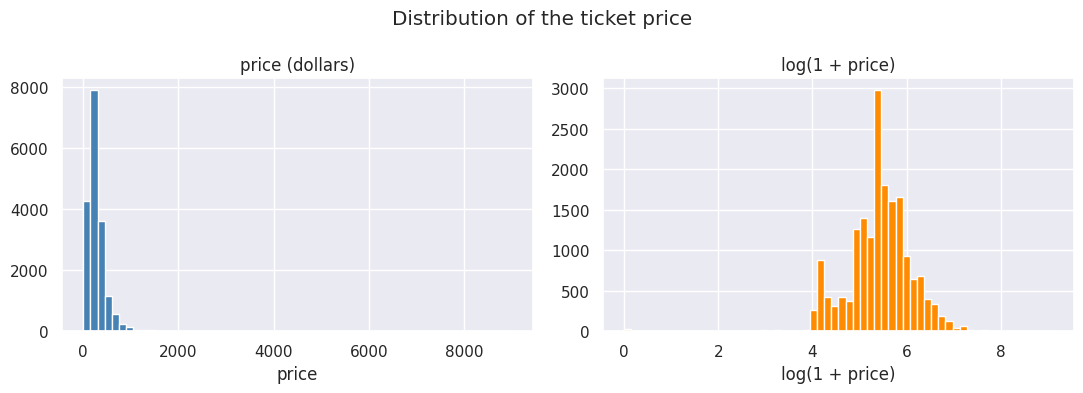

In [36]:
price_stats = pd.Series(
    {
        "count": train["price"].count(),
        "mean": train["price"].mean(),
        "std": train["price"].std(),
        "min": train["price"].min(),
        "median": train["price"].median(),
        "max": train["price"].max(),
        "skewness": train["price"].skew(),
        "kurtosis": train["price"].kurtosis(),
        "non_positive values": int((train["price"] <= 0).sum()),
    }
).round(2)
print(price_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train["price"], bins=60, color="steelblue")
axes[0].set_title("price (dollars)")
axes[0].set_xlabel("price")
axes[1].hist(np.log1p(train["price"]), bins=60, color="darkorange")
axes[1].set_title("log(1 + price)")
axes[1].set_xlabel("log(1 + price)")
fig.suptitle("Distribution of the ticket price")
fig.tight_layout()
fig.savefig(FIGURES / "flight_price_distribution.png", dpi=150)
plt.show()

As the histogram above shows, most tickets are concentrated below USD 400,
while a small number of fares run up to USD 8,996 against a median of only
USD 234.

Skewness = 7.07 and Kurtosis = 170.25. This shows that a small number of very expensive tickets sit far above the rest of the fares. 

Since the models will be scored with squared error, these few expensive tickets can dominate the score.

### 2.2 Feature-wise Analysis

Next we look at the two numeric features and at how price behaves across
the categorical ones.

       duration  days_left
count  18076.00   18076.00
mean       2.75      20.52
std        2.95      12.09
min        0.87       1.00
25%        1.47      10.00
50%        1.63      20.00
75%        2.00      31.00
max       28.65      44.00


corr(duration, price) = 0.281
corr(days_left, price) = -0.229


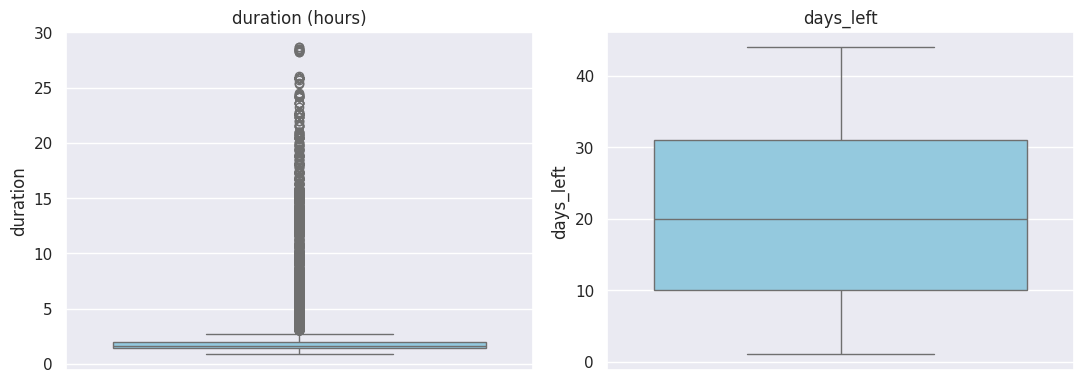

In [7]:
show_table(train[["duration", "days_left"]].describe().round(2))
print("corr(duration, price) =", round(train["duration"].corr(train["price"]), 3))
print("corr(days_left, price) =", round(train["days_left"].corr(train["price"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=train["duration"], ax=axes[0], color="skyblue")
axes[0].set_title("duration (hours)")
sns.boxplot(y=train["days_left"], ax=axes[1], color="skyblue")
axes[1].set_title("days_left")
fig.tight_layout()
fig.savefig(FIGURES / "flight_feature_boxplots.png", dpi=150)
plt.show()

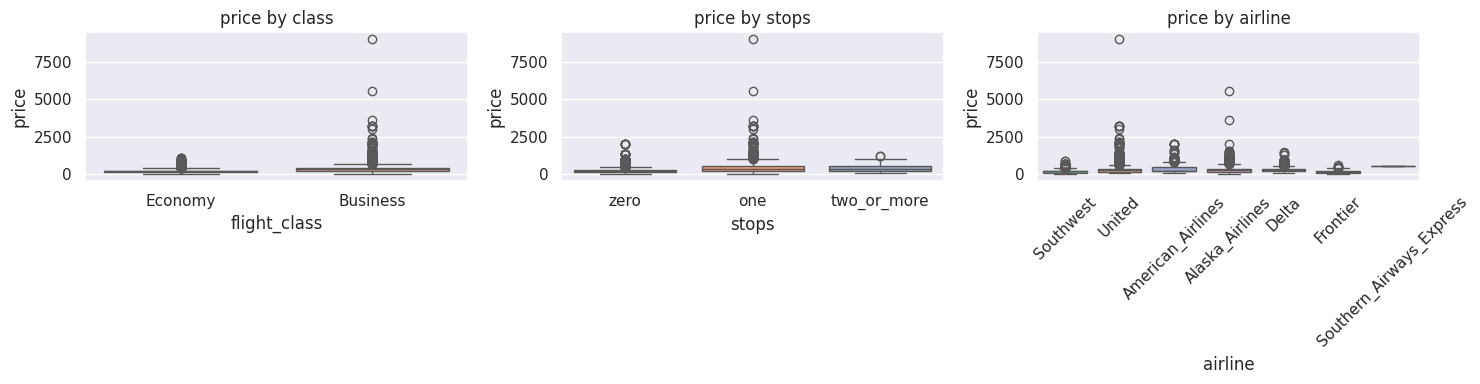

              count   mean  median
flight_class                      
Business       7365  394.0   323.0
Economy       10711  202.1   194.0


             count   mean  median
stops                            
one           4324  431.5   347.0
two_or_more    193  425.7   370.0
zero         13559  230.0   214.0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=train, x="flight_class", y="price", hue="flight_class",
            legend=False, ax=axes[0], palette="Set2")
axes[0].set_title("price by class")
sns.boxplot(data=train, x="stops", y="price", hue="stops",
            legend=False, ax=axes[1], palette="Set2")
axes[1].set_title("price by stops")
sns.boxplot(data=train, x="airline", y="price", hue="airline",
            legend=False, ax=axes[2], palette="Set2")
axes[2].set_title("price by airline")
axes[2].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES / "flight_price_by_category.png", dpi=150)
plt.show()

show_table(train.groupby("flight_class")["price"].agg(["count", "mean", "median"]).round(1))
show_table(train.groupby("stops")["price"].agg(["count", "mean", "median"]).round(1))

Observations:

- **Class**: Business tickets are clearly higher in price, with a median near USD 320, against USD 194 for Economy, and Business is also the group where the very expensive fares (up to USD 8,996) appear.
- **Stops**: Non-stop flights have a median near USD 214, while one-stop and two-or-more-stop itineraries are around USD 347 and USD 370. Only 193 flights have two or more stops, so that group is small relatively.
- **Airline**: Medians range from about USD 168 for Frontier up to about USD 260 for United, Delta and Alaska. `Southern_Airways_Express` appears exactly once in the training data, so nothing general can be learned for it.
- **Duration** ranges from 0.87 to 28.65 hours, though a few flights run much longer than the rest, and days_left spreads fairly evenly from 1 to 44 days. Neither relates strongly to price: their linear correlations are only +0.281 and -0.229.

### 2.3 Correlation Analysis

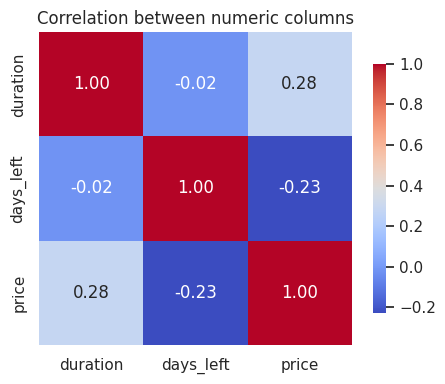

In [9]:
fig, axis = plt.subplots(figsize=(5, 4))
sns.heatmap(train[["duration", "days_left", "price"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", square=True, ax=axis, cbar_kws={"shrink": 0.8})
axis.set_title("Correlation between numeric columns")
fig.tight_layout()
fig.savefig(FIGURES / "flight_correlation.png", dpi=150)
plt.show()

No pair of numeric columns is strongly linearly related. The largest correlation with price is +0.28, for duration.

### 2.4 High-cardinality Columns

In [10]:
print(train.select_dtypes(exclude="number").nunique().to_string())
unseen_flight_codes = sorted(set(test["flight"]) - set(train["flight"]))
print("\nflight codes that appear only in test:", len(unseen_flight_codes))
print(unseen_flight_codes[:5])

airline                7
flight              1123
source_city            5
departure_time         6
stops                  3
arrival_time           6
destination_city       5
flight_class           2

flight codes that appear only in test: 33
['AA 2785', 'AS 3144', 'AS 698', 'DL 1260', 'DL 1296']


The `flight` column has 1,123 distinct codes (33 of them appear only in the
test file).

Treating it as a category would create over a thousand sparse columns and the unseen codes would have no coefficients at all.

## 3. Data Cleaning

25 training rows carry a price of 0. Since a ticket cannot cost nothing, these look like entry errors and are removed.

In [11]:
rows_before = len(train)
train = train[train["price"] > 0].reset_index(drop=True)
print(f"removed {rows_before - len(train)} rows with price <= 0; {len(train)} rows remain")

train_ids = train["id"]
test_ids = test["id"]
y_train = train["price"]
X_train = train.drop(columns=["price", "id"])
X_test = test.drop(columns=["id"])

removed 25 rows with price <= 0; 18051 rows remain


## 4. Feature Engineering

Three features are prepared using existing columns:

1. **airline_code** and **flight_number** from the flight code. The code "WN 3596" contains the carrier ("WN") and a serial number; airlines tend to reuse numbers for the same route, so the number can carry route information that the city columns alone do not show.
2. **stops_ordinal**: stops is one-hot encoded during preprocessing for the regression models.
3. **route**: source and destination are merged into one category. The same city pair shares a fare level, and a single merged column can help the tree-based models split on particular city pairs.

In [37]:
def add_flight_features(df):
    """Create airline code, flight number, ordinal stops and route."""
    out = df.copy()
    out["airline_code"] = out["flight"].str.split().str[0]
    out["flight_number"] = pd.to_numeric(out["flight"].str.extract(r"(\d+)")[0], errors="coerce")
    out["stops_ordinal"] = out["stops"].map({"zero": 0, "one": 1, "two_or_more": 2})
    out["route"] = out["source_city"] + "_" + out["destination_city"]
    return out

X_train = add_flight_features(X_train)
X_test = add_flight_features(X_test)
print("feature frame with engineered columns:", X_train.shape)
show_table(X_train.head(3))

feature frame with engineered columns: (18051, 14)
     airline   flight source_city departure_time stops arrival_time destination_city flight_class  duration  days_left airline_code  flight_number  stops_ordinal                    route
0  Southwest  WN 3596    San Jose  Early_Morning  zero      Morning      Los Angeles      Economy      1.33          5           WN           3596              0     San Jose_Los Angeles
1  Southwest  WN 1307    San Jose        Evening  zero      Evening        San Diego      Economy      1.58         40           WN           1307              0       San Jose_San Diego
2     United  UA 1763   San Diego      Afternoon  zero    Afternoon    San Francisco      Economy      1.77          2           UA           1763              0  San Diego_San Francisco


## 5. Data Preprocessing

The preprocessing is done with scikit-learn `ColumnTransformer` and used inside a `Pipeline`, so during cross-validation every transformation is fitted on the training sets only (and not the validation sets).

1. Numeric columns are standardised (scaling-wise) for the models that need it (Ridge, Lasso). Both penalties act on the size of the coefficients, so features on different scales would otherwise be treated unequally. Trees split on thresholds and do not need scaling.
2. Categorical columns are one-hot encoded.
3. High-cardinality columns (more than 100 levels) are dropped here. flight is the only such column.

In [13]:
def build_preprocessor(df, scale_numeric=True, max_cardinality=100):
    """Build the imputation and encoding transformer for a feature frame."""
    numeric = df.select_dtypes(include="number").columns.tolist()
    categorical = df.select_dtypes(exclude="number").columns.tolist()
    dropped = [column for column in categorical if df[column].nunique() > max_cardinality]
    if dropped:
        print("dropping high-cardinality columns:", dropped)
    categorical = [column for column in categorical if column not in dropped]

    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [
            ("num", Pipeline(numeric_steps), numeric),
            (
                "cat",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        ("encode", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
    )


scaled = build_preprocessor(X_train, scale_numeric=True)
plain = build_preprocessor(X_train, scale_numeric=False)
print("encoded feature matrix:", scaled.fit_transform(X_train).shape)

dropping high-cardinality columns: ['flight']
dropping high-cardinality columns: ['flight']
encoded feature matrix: (18051, 63)


## 6. Model Evaluation (Reusable Functions)

The metrics are RMSE, MAE and R2, all computed with 5-fold cross-validation. We use cross-validation instead of a single train-validation split so that every row is validated exactly once and the five scores give a more stable estimate.

In [14]:
SCORING = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}


def make_folds(n_splits=5, n_repeats=1):
    """Shuffled k-fold, or repeated k-fold when n_repeats > 1."""
    if n_repeats > 1:
        return RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=SEED)
    return KFold(n_splits=n_splits, shuffle=True, random_state=SEED)


LOG = []


def cross_validate_model(name, model, metric="rmse", n_splits=5, n_repeats=1, note=""):
    """Cross-validate one model and record the result."""
    scores = cross_validate(
        clone(model), X_train, y_train, cv=make_folds(n_splits, n_repeats),
        scoring=SCORING[metric], n_jobs=1, error_score="raise",
    )
    values = np.asarray(scores["test_score"], dtype=float)
    if SCORING[metric].startswith("neg_"):
        values = -values
    row = {
        "model": name,
        "metric": metric,
        "mean": round(float(values.mean()), 5),
        "std": round(float(values.std()), 5),
        "fold_scores": [round(float(v), 3) for v in values],
        "n_repeats": n_repeats,
        "note": note,
    }
    LOG.append(row)
    return row


def cross_validate_metrics(name, model, metrics=("rmse", "mae", "r2"), n_splits=5):
    """Evaluate several metrics for one model in a single cross-validation pass."""
    scores = cross_validate(
        clone(model), X_train, y_train, cv=make_folds(n_splits, 1),
        scoring={metric: SCORING[metric] for metric in metrics},
        n_jobs=1, error_score="raise",
    )
    row = {"model": name}
    for metric in metrics:
        values = np.asarray(scores[f"test_{metric}"], dtype=float)
        if SCORING[metric].startswith("neg_"):
            values = -values
        row[metric] = round(float(values.mean()), 4)
    return row


def save_figure(fig, name):
    """Save a figure into figures/ and keep it open for inline display."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150)
    print("saved figures/" + name)


def fit_and_write_submission(name, model):
    """Fit the model on all training rows and write a template-aligned CSV."""
    fitted = clone(model).fit(X_train, y_train)
    predictions = fitted.predict(X_test)
    submission = template[["id"]].copy()
    submission["price"] = np.asarray(predictions)
    assert len(submission) == len(template)
    assert submission["price"].notna().all()
    assert set(submission["id"]) == set(template["id"])
    path = SUBMISSIONS / f"submission_{name}.csv"
    submission.to_csv(path, index=False)
    return path


print("helper functions ready")

helper functions ready


## 7. Model Family Direct Comparisons (Baseline)

We train the following models once, with reasonable default settings:

- **Linear Regression (Ordinary Least Squares)**: the closed-form least-squares solution.
- **Polynomial Regression (degree 2)**: least squares on squared and interaction terms of the encoded features.
- **Ridge Regression (L2)**: least squares with an L2 penalty on the coefficients, which shrinks them towards zero.
- **Lasso Regression (L1)**: least squares with an L1 penalty, which can set coefficients exactly to zero.
- **Decision Tree**: recursive binary splitting on the features.
- **Random Forest**: many trees on bootstrap samples with random feature subsets, averaged.

In [15]:
baseline_models = {
    "linear_regression_ols": Pipeline([("prep", scaled), ("model", LinearRegression())]),
    "poly_reg_degree2": Pipeline([
        ("prep", scaled),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression()),
    ]),
    "ridge_reg_l2": Pipeline([("prep", scaled), ("model", Ridge(alpha=1.0, random_state=SEED))]),
    "lasso_reg_l1": Pipeline([
        ("prep", scaled),
        ("model", Lasso(alpha=0.1, max_iter=20000, random_state=SEED)),
    ]),
    "decision_tree": Pipeline([
        ("prep", plain),
        ("model", DecisionTreeRegressor(random_state=SEED)),
    ]),
    "random_forest_300": Pipeline([
        ("prep", plain),
        ("model", RandomForestRegressor(n_estimators=300, max_features="sqrt",
                                        random_state=SEED, n_jobs=-1)),
    ]),
}

baseline_rows = [cross_validate_model(name, model, note="direct comparison") for name, model in baseline_models.items()]
baseline_table = pd.DataFrame(baseline_rows).sort_values("mean").reset_index(drop=True)
show_table(baseline_table[["model", "metric", "mean", "std"]])

                   model metric       mean       std
0      random_forest_300   rmse  128.97150  27.83387
1           ridge_reg_l2   rmse  153.64256  27.23077
2           lasso_reg_l1   rmse  154.29985  27.53269
3  linear_regression_ols   rmse  154.82206  25.75994
4          decision_tree   rmse  158.24697  30.03604
5       poly_reg_degree2   rmse  177.25349  31.52622

saved figures/flight_model_comparison.png


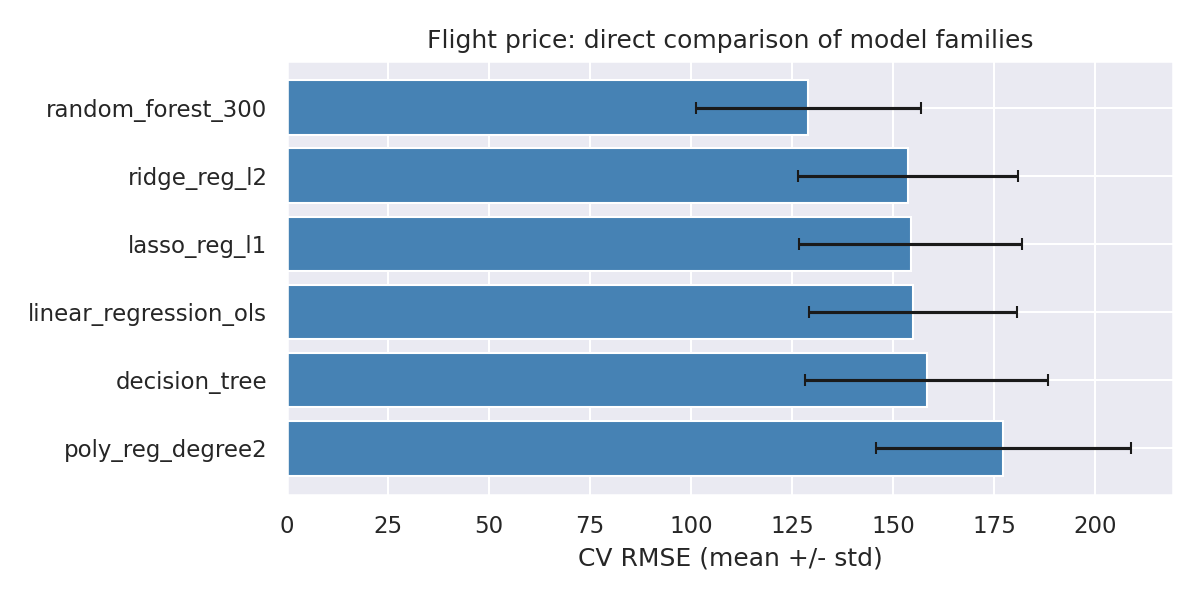

In [16]:
fig, axis = plt.subplots(figsize=(8, 4))
ordered = baseline_table.sort_values("mean", ascending=False)
axis.barh(ordered["model"], ordered["mean"], xerr=ordered["std"], capsize=3, color="steelblue")
axis.set_xlabel("CV RMSE (mean +/- std)")
axis.set_title("Flight price: direct comparison of model families")
save_figure(fig, "flight_model_comparison.png")
plt.show()

The random forest model is already better than everything else (around 128 RMSE against about 154 or higher for the rest).

Polynomial regression without a penalty is worse than plain linear regression, a first sign that the expansion needs a penalty before it becomes useful.

The single unconstrained tree ends up overfitting, scoring about 158, close to the linear models.

## 8. Hyper-parameter Tuning

In this section each model family is tuned on its own.

### 8.1 Polynomial Regression: Optimal Degree

The degree controls how much curvature and interaction the model can represent: degree 1 is a straight line, degree 2 adds squares and pairwise products, degree 3 adds triple products. A high degree without a penalty has too much complexity and overfits.

penalty  L2 (lambda=1)   none
degree                       
1                153.6  154.8
2                136.7  177.3
3                158.0  380.9


saved figures/flight_poly_degree.png


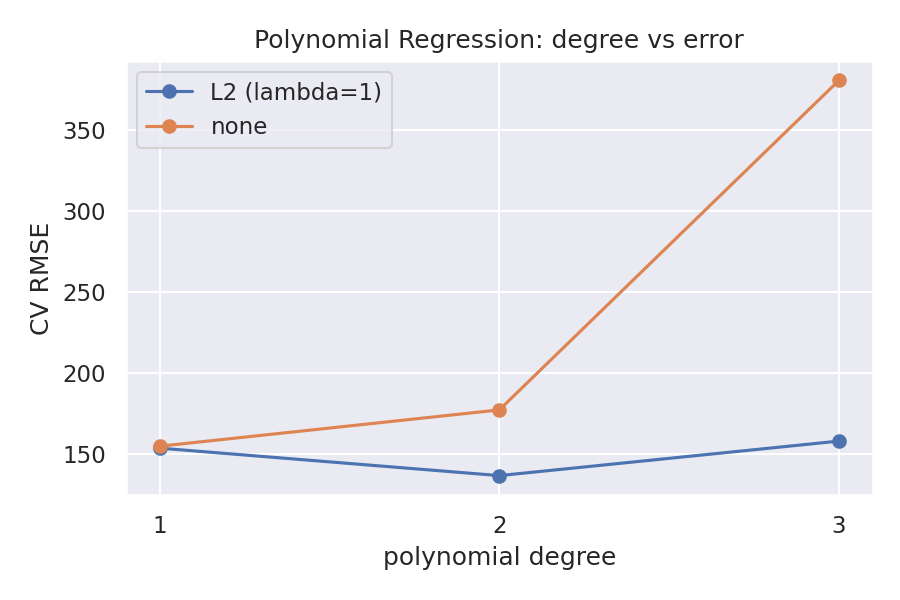

In [17]:
degree_rows = []
for degree in [1, 2, 3]:
    model = Pipeline([
        ("prep", scaled),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", LinearRegression()),
    ])
    row = cross_validate_model(f"poly_reg_degree{degree}", model, note="degree sweep")
    degree_rows.append({"degree": degree, "penalty": "none", "mean": row["mean"], "std": row["std"]})

    model = Pipeline([
        ("prep", scaled),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("model", Ridge(alpha=1.0, random_state=SEED)),
    ])
    row = cross_validate_model(f"poly_reg_degree{degree}_l2", model, note="degree sweep")
    degree_rows.append({"degree": degree, "penalty": "L2 (lambda=1)", "mean": row["mean"], "std": row["std"]})

degree_table = pd.DataFrame(degree_rows)
show_table(degree_table.pivot(index="degree", columns="penalty", values="mean").round(1))

fig, axis = plt.subplots(figsize=(6, 4))
for penalty, group in degree_table.groupby("penalty"):
    axis.plot(group["degree"], group["mean"], marker="o", label=penalty)
axis.set_xticks([1, 2, 3])
axis.set_xlabel("polynomial degree")
axis.set_ylabel("CV RMSE")
axis.set_title("Polynomial Regression: degree vs error")
axis.legend()
save_figure(fig, "flight_poly_degree.png")
plt.show()

Observations
- Degree 1 (a straight line) gives 154.8 RMSE.
- Degree 2 without a penalty is worse than degree 1 at 177.3 RMSE.
- Degree 3 without a penalty collapses to 380.9 RMSE.
- The same degree-2 expansion with an L2 penalty (lambda = 1) gives 136.7 RMSE (best yet).

### 8.2 Ridge Regression (L2): Optimal Lambda

Ridge minimises the squared error plus lambda times the squared coefficient
norm.

saved figures/flight_ridge_lambda.png


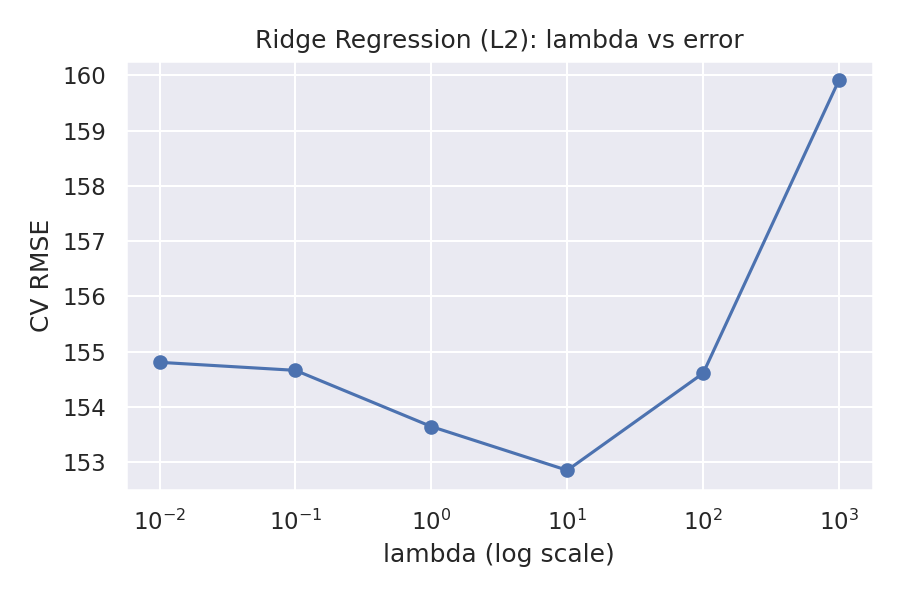

In [18]:
ridge_rows = []
for lam in [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]:
    model = Pipeline([("prep", scaled), ("model", Ridge(alpha=lam, random_state=SEED))])
    row = cross_validate_model(f"ridge_reg_l2_lambda{lam}", model, note="lambda sweep")
    ridge_rows.append({"lambda": lam, "mean": row["mean"], "std": row["std"]})

ridge_table = pd.DataFrame(ridge_rows).sort_values("mean").reset_index(drop=True)
show_table(ridge_table)

fig, axis = plt.subplots(figsize=(6, 4))
axis.plot(ridge_table.sort_values("lambda")["lambda"], ridge_table.sort_values("lambda")["mean"], marker="o")
axis.set_xscale("log")
axis.set_xlabel("lambda (log scale)")
axis.set_ylabel("CV RMSE")
axis.set_title("Ridge Regression (L2): lambda vs error")
save_figure(fig, "flight_ridge_lambda.png")
plt.show()

The curve is flat between lambda = 1 and 100 (152.9 to 154.6 RMSE), with the best single value at lambda = 10 (152.9).

Only at lambda = 1000 does the penalty become strong enough to underfit visibly (159.9).

### 8.3 Lasso Regression (L1): Optimal Lambda

Lasso adds an L1 penalty instead. The L1 penalty can push coefficients exactly to zero, which removes features from the model. After that, we refit the best value and count how many encoded features keep a non-zero coefficient.

   lambda       mean       std
0  0.5000  154.10661  31.54079
1  0.1000  154.29985  27.53269
2  0.0500  154.52563  26.66101
3  0.0100  154.75631  25.94222
4  0.0010  154.81508  25.77836
5  0.0001  154.82121  25.76193
6  1.0000  156.38702  30.67776


dropping high-cardinality columns: ['flight']
best lambda = 0.5; non-zero coefficients: 42 of 63
saved figures/flight_lasso_lambda.png


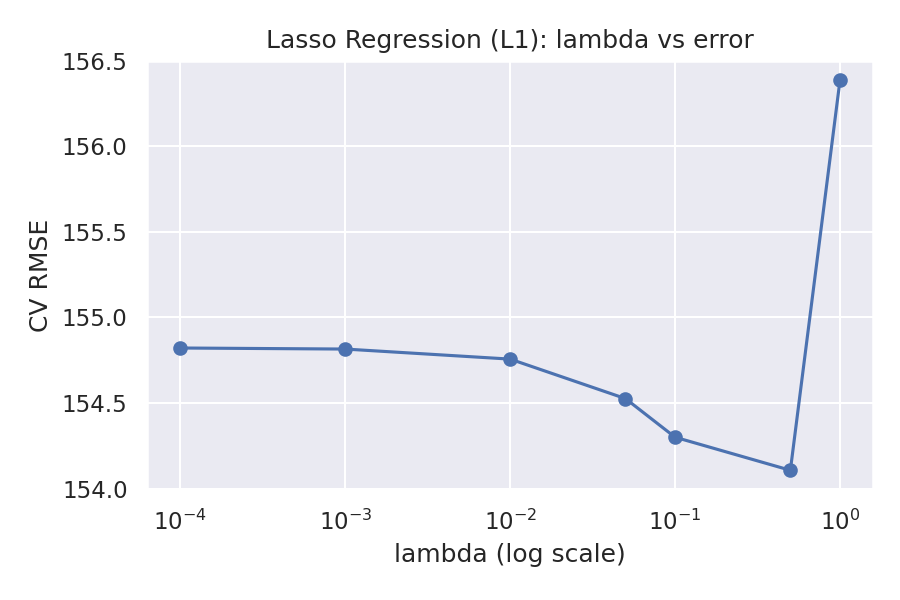

In [19]:
lasso_rows = []
for lam in [1e-4, 1e-3, 0.01, 0.05, 0.1, 0.5, 1.0]:
    model = Pipeline([
        ("prep", scaled),
        ("model", Lasso(alpha=lam, max_iter=20000, random_state=SEED)),
    ])
    row = cross_validate_model(f"lasso_reg_l1_lambda{lam}", model, note="lambda sweep")
    lasso_rows.append({"lambda": lam, "mean": row["mean"], "std": row["std"]})

lasso_table = pd.DataFrame(lasso_rows).sort_values("mean").reset_index(drop=True)
show_table(lasso_table)

best_lasso_lambda = float(lasso_table.iloc[0]["lambda"])
lasso_fitted = Pipeline([
    ("prep", build_preprocessor(X_train, scale_numeric=True)),
    ("model", Lasso(alpha=best_lasso_lambda, max_iter=20000, random_state=SEED)),
]).fit(X_train, y_train)
coefficients = np.abs(np.asarray(lasso_fitted.named_steps["model"].coef_).ravel())
total_features = len(lasso_fitted.named_steps["prep"].get_feature_names_out())
print(f"best lambda = {best_lasso_lambda}; "
      f"non-zero coefficients: {int((coefficients > 1e-12).sum())} of {total_features}")

fig, axis = plt.subplots(figsize=(6, 4))
axis.plot(lasso_table.sort_values("lambda")["lambda"], lasso_table.sort_values("lambda")["mean"], marker="o")
axis.set_xscale("log")
axis.set_xlabel("lambda (log scale)")
axis.set_ylabel("CV RMSE")
axis.set_title("Lasso Regression (L1): lambda vs error")
save_figure(fig, "flight_lasso_lambda.png")
plt.show()

Lasso tops out at lambda = 0.5 with 154.1 RMSE, slightly behind Ridge, and keeps 42 of the 63 encoded features non-zero. That is the L1 behaviour from the notes in practice: a large share of the one-hot columns are simply switched off. At the smallest lambdas the solver printed convergence warnings, which makes sense because the target is on a dollar scale and the tolerances in the solver are relative to it.

### 8.4 Decision Tree

#### 8.4.1 Pre-pruning: Depth, Leaf Size, Split Size, Maximum Leaves

An unrestricted tree grows until its leaves have single values, which memorises the training data. Pre-pruning limits the growth beforehand.

Four limits are tuned together: maximum depth, minimum samples per leaf, minimum samples needed to split a node, and the maximum number of leaves.

In [20]:
tree_rows = []
for depth in [8, 12, 16, None]:
    for leaf in [1, 5, 20]:
        for split in [2, 10]:
            for max_leaves in [None, 50]:
                model = Pipeline([
                    ("prep", plain),
                    ("model", DecisionTreeRegressor(
                        max_depth=depth, min_samples_leaf=leaf,
                        min_samples_split=split, max_leaf_nodes=max_leaves,
                        random_state=SEED)),
                ])
                name = f"decision_tree_d{depth}_l{leaf}_s{split}_ml{max_leaves}"
                row = cross_validate_model(name, model, note="pre-pruning grid")
                tree_rows.append({"max_depth": depth, "min_samples_leaf": leaf,
                                  "min_samples_split": split, "max_leaf_nodes": max_leaves,
                                  "mean": row["mean"], "std": row["std"]})

tree_table = pd.DataFrame(tree_rows).sort_values("mean").reset_index(drop=True)
print("best pre-pruned trees:")
show_table(tree_table.head(5))

best pre-pruned trees:


   max_depth  min_samples_leaf  min_samples_split  max_leaf_nodes       mean  \
0       12.0                 5                 10             NaN  128.81897   
1       12.0                 5                  2             NaN  128.81897   
2       16.0                 5                 10             NaN  128.99794   
3       16.0                 5                  2             NaN  128.99794   
4       12.0                 1                 10             NaN  129.18372   

        std  
0  31.53518  
1  31.53518  
2  31.39847  
3  31.39847  
4  27.05921  


The grid peaks at depth 12 with a minimum leaf size of 5, around 128.8
RMSE. Fully grown trees (no depth limit, leaf size 1) are the worst row at
about 158, and shallow depth-4 trees underfit at 149 to 163 depending on
the leaf size. The extra knobs, `min_samples_split` and `max_leaf_nodes`,
change nothing once depth and leaf size are fixed. This is the U-shaped
bias-variance trade-off in numbers.

#### 8.4.2 Post-pruning: Cost-complexity Pruning (lambda)

The tree is grown fully and then subtrees are cut back. Each subtree costs one extra parameter per leaf, and the cost-complexity criterion is

```
R_lambda(T) = R(T) + lambda * |T|
```

where R(T) is the training error of the tree and |T| is its number of leaves.

      lambda       mean       std
0  66.218434  148.39205  30.52943
1  29.283112  148.95329  30.89633
2  12.949576  150.27326  30.37866
3   5.726561  152.74137  30.00600
4   2.532399  154.86717  30.06347


best pruning lambda = 66.21843372: 66 leaves, depth 11
saved figures/flight_tree_pruning.png


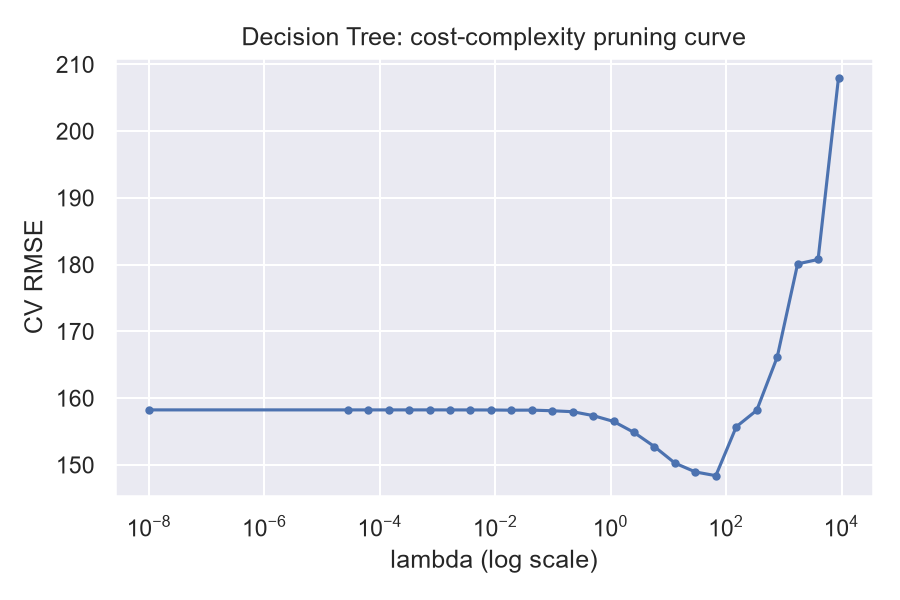

In [21]:
encoded = plain.fit_transform(X_train)
path = DecisionTreeRegressor(random_state=SEED).cost_complexity_pruning_path(encoded, y_train)
positive_lambdas = path.ccp_alphas[path.ccp_alphas > 0]
lambda_candidates = [0.0] + [
    float(value) for value in np.round(np.geomspace(positive_lambdas.min(), positive_lambdas.max(), 25), 8)
]

ccp_rows = []
for lam in lambda_candidates:
    model = Pipeline([
        ("prep", plain),
        ("model", DecisionTreeRegressor(ccp_alpha=lam, random_state=SEED)),
    ])
    row = cross_validate_model(f"decision_tree_post_lambda{lam}", model, note="post-pruning sweep")
    ccp_rows.append({"lambda": lam, "mean": row["mean"], "std": row["std"]})

ccp_table = pd.DataFrame(ccp_rows).sort_values("mean").reset_index(drop=True)
show_table(ccp_table.head(5))

best_ccp_lambda = float(ccp_table.iloc[0]["lambda"])
ccp_tree = Pipeline([
    ("prep", plain),
    ("model", DecisionTreeRegressor(ccp_alpha=best_ccp_lambda, random_state=SEED)),
])
fitted_ccp = clone(ccp_tree).fit(X_train, y_train)
print(
    f"best pruning lambda = {best_ccp_lambda}: "
    f"{fitted_ccp.named_steps['model'].get_n_leaves()} leaves, "
    f"depth {fitted_ccp.named_steps['model'].get_depth()}"
)

ccp_curve = ccp_table.sort_values("lambda")
fig, axis = plt.subplots(figsize=(6, 4))
axis.plot(ccp_curve["lambda"].clip(lower=1e-8), ccp_curve["mean"], marker="o", markersize=3)
axis.set_xscale("log")
axis.set_xlabel("lambda (log scale)")
axis.set_ylabel("CV RMSE")
axis.set_title("Decision Tree: cost-complexity pruning curve")
save_figure(fig, "flight_tree_pruning.png")
plt.show()

Pruning back to 66 leaves (lambda = 66.2) gives about 148 RMSE, clearly worse than the pre-pruned tree at 128.8.

The pre-pruned tree is kept for the rest of the notebook.

### 8.5 Random Forest

This method averages many decorrelated trees.

The grid varies the number of trees and the minimum leaf size. The depth is left unconstrained, because the minimum leaf size already limits the size of these trees.

In [22]:
forest_rows = []
for n_estimators in [200, 400]:
    for leaf in [1, 3]:
        model = Pipeline([
            ("prep", plain),
            ("model", RandomForestRegressor(
                n_estimators=n_estimators, min_samples_leaf=leaf,
                max_features="sqrt", random_state=SEED, n_jobs=-1)),
        ])
        name = f"random_forest_trees{n_estimators}_leaf{leaf}"
        row = cross_validate_model(name, model, note="random forest grid")
        forest_rows.append({"n_estimators": n_estimators,
                            "min_samples_leaf": leaf, "mean": row["mean"], "std": row["std"]})

forest_table = pd.DataFrame(forest_rows).sort_values("mean").reset_index(drop=True)
show_table(forest_table.head(6))

   n_estimators  min_samples_leaf       mean       std
0           400                 3  121.37290  30.63380
1           200                 3  121.57657  30.82911
2           200                 1  128.76859  27.75169
3           400                 1  128.81029  27.89028

Every configuration with leaf size 3 scores around 121.5 RMSE, while leaf size 1 has nearly 129.

Doubling the number of trees from 200 to 400 changes the score by a fraction of an RMSE unit, so we use the version with 400 trees and leaf size 3.

In [23]:
best_forest_params = forest_table.iloc[0].to_dict()
print("selected forest:", {key: best_forest_params[key] for key in ["n_estimators", "min_samples_leaf"]})

selected forest: {'n_estimators': 400.0, 'min_samples_leaf': 3.0}


## 9. Experiment: Regression on log(price)

A handful of tickets cost more than USD 8,000 while the median is USD 234, so with squared error, those rows have an outsized weight.

One way to distribute this evenly is to train on `log(1 + price)` and convert the predictions back to dollars afterwards, so the model is effectively fitted on relative errors.

In [24]:
def with_log_target(pipeline):
    """Fit the pipeline on log(1 + price) and predict back in dollars."""
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)


log_rows = []
for degree in [1, 2]:
    for lam in [0.1, 1.0, 10.0, 100.0]:
        model = with_log_target(Pipeline([
            ("prep", scaled),
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("model", Ridge(alpha=lam, random_state=SEED)),
        ]))
        row = cross_validate_model(f"log_price_ridge_deg{degree}_lambda{lam}", model, note="log-price experiment")
        log_rows.append({"degree": degree, "lambda": lam, "mean": row["mean"], "std": row["std"]})

log_table = pd.DataFrame(log_rows).sort_values("mean").reset_index(drop=True)
best_log_params = log_table.iloc[0].to_dict()
show_table(log_table.head(5))
print("best log-price configuration:", {key: best_log_params[key] for key in ["degree", "lambda"]})

best_log_ridge = with_log_target(Pipeline([
    ("prep", scaled),
    ("poly", PolynomialFeatures(degree=int(best_log_params["degree"]), include_bias=False)),
    ("model", Ridge(alpha=float(best_log_params["lambda"]), random_state=SEED)),
]))
log_r2 = cross_validate_model("log_price_ridge_best", best_log_ridge, metric="r2", note="best log-price model")
print(f"best log-price model R2 = {log_r2['mean']} +/- {log_r2['std']}")

   degree  lambda       mean       std
0       2    10.0  124.96408  29.26934
1       2   100.0  128.06121  31.43749
2       2     1.0  130.14570  25.76747
3       2     0.1  148.24325  27.62161
4       1     0.1  148.98508  25.88057


best log-price configuration: {'degree': 2.0, 'lambda': 10.0}
best log-price model R2 = 0.68243 +/- 0.07403


The best configuration is degree 2 with lambda = 10, at about 125.0 RMSE and R2 = 0.6824, against 136.7 for the degree-2 Ridge on the raw price.

Even after this gain, the random forest model (about 121.4 RMSE) is better overall, so this is the strongest linear model rather than the overall best.

## 10. Experiment: Ensemble of Random Forest and Polynomial Ridge

We wanted to see if averaging their predictions can cancel part of each model's individual error.

Two combinations are tried - random forest together with the log-price Ridge, and the same pair plus a plain Ridge as a third member.

In [25]:
forest_final = Pipeline([
    ("prep", plain),
    ("model", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                    max_features="sqrt", random_state=SEED, n_jobs=-1)),
])
ridge_lambda10 = Pipeline([("prep", scaled), ("model", Ridge(alpha=10.0, random_state=SEED))])

cross_validate_model("random_forest_final", forest_final, note="reference for the ensemble")
cross_validate_model("ensemble_forest_log_ridge",
                     VotingRegressor([("forest", forest_final), ("log_price_ridge", best_log_ridge)]),
                     note="forest + log-price ridge")
cross_validate_model("ensemble_forest_log_ridge_plain_ridge",
                     VotingRegressor([("forest", forest_final), ("log_price_ridge", best_log_ridge),
                                      ("ridge", ridge_lambda10)]),
                     note="forest + log-price ridge + ridge")

ensemble_rows = [row for row in LOG if "ensemble" in row["model"] or row["model"] == "random_forest_final"]
show_table(pd.DataFrame(ensemble_rows)[["model", "mean", "std"]])

                                   model       mean       std
0                    random_forest_final  121.37290  30.63380
1              ensemble_forest_log_ridge  120.00566  30.68943
2  ensemble_forest_log_ridge_plain_ridge  125.74766  31.11304

The two-member average scores about 120.0 RMSE, slightly better than random forest alone at 121.4, while the three-member average scores about 125.7.

Since the gap is fairly low, in favor of lesser complexity, we keep the single random forest model as our best.

## 11. Model Diagnostics

### 11.1 Predicted vs Actual (out-of-fold)

Each point below is a training row predicted by a model that did not see it
(out-of-fold predictions). The red line marks perfect prediction.

saved figures/flight_pred_vs_actual.png


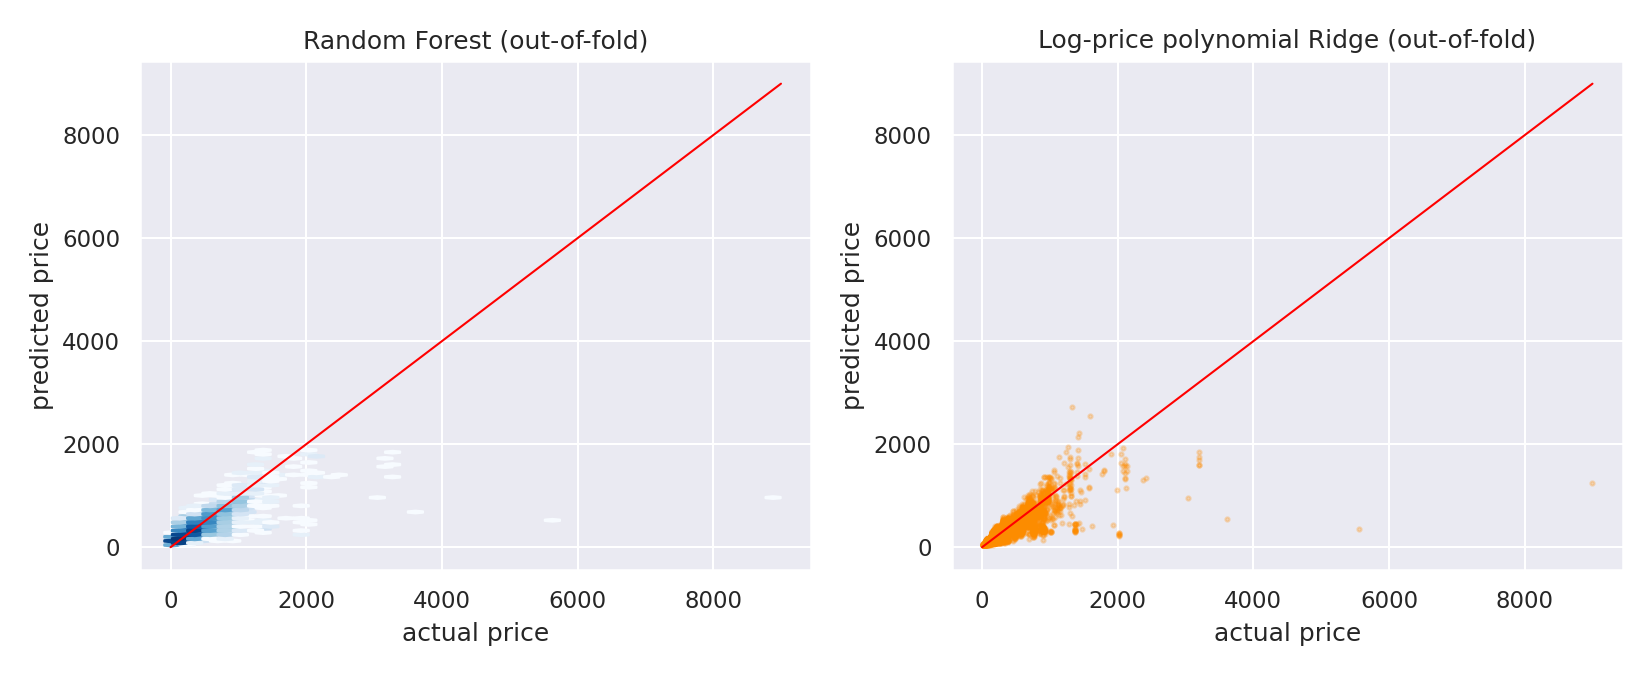

In [26]:
def out_of_fold_predictions(model):
    """Collect one out-of-fold prediction per training row."""
    return cross_val_predict(clone(model), X_train, y_train,
                             cv=make_folds(5, 1), n_jobs=-1)


forest_pred = out_of_fold_predictions(forest_final)
logridge_pred = out_of_fold_predictions(best_log_ridge)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hexbin(y_train, forest_pred, gridsize=40, bins="log", cmap="Blues")
axes[0].plot([0, 9000], [0, 9000], color="red", linewidth=1)
axes[0].set_xlabel("actual price")
axes[0].set_ylabel("predicted price")
axes[0].set_title("Random Forest (out-of-fold)")
axes[1].scatter(y_train, logridge_pred, s=4, alpha=0.25, color="darkorange")
axes[1].plot([0, 9000], [0, 9000], color="red", linewidth=1)
axes[1].set_xlabel("actual price")
axes[1].set_ylabel("predicted price")
axes[1].set_title("Log-price polynomial Ridge (out-of-fold)")
save_figure(fig, "flight_pred_vs_actual.png")
plt.show()

Both panels show the same pattern: the dense cloud of points sits close to the diagonal for ordinary fares (up to roughly USD 1,500), and both models fall below the line for the expensive tickets, meaning they under-predictthe rare high fares.

The forest predictions rarely go above USD 2,000 even when the actual price is far higher, which is expected: a tree can only average leaf values, and expensive tickets are too rare to form their own confident leaves.

The log-price Ridge stretches a little further into the mid-range but still flattens at the top.

### 11.2 Residual Analysis (Random Forest)

saved figures/flight_residuals.png
mean residual: -0.18
largest residual: 8032.39


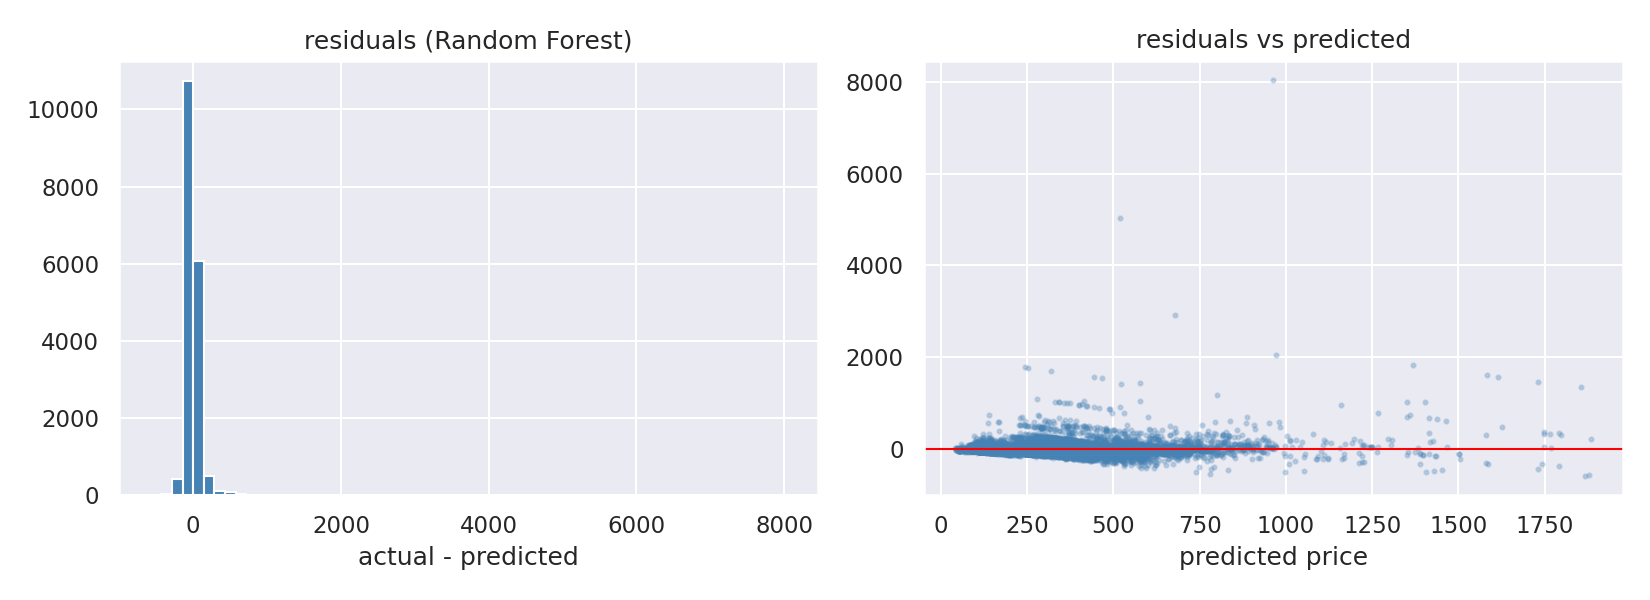

In [27]:
residuals = y_train - forest_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(residuals, bins=60, color="steelblue")
axes[0].set_title("residuals (Random Forest)")
axes[0].set_xlabel("actual - predicted")
axes[1].scatter(forest_pred, residuals, s=4, alpha=0.25, color="steelblue")
axes[1].axhline(0, color="red", linewidth=1)
axes[1].set_title("residuals vs predicted")
axes[1].set_xlabel("predicted price")
save_figure(fig, "flight_residuals.png")
plt.show()

print("mean residual:", round(float(residuals.mean()), 2))
print("largest residual:", round(float(residuals.max()), 2))

The residual histogram is centred close to zero, with a small number of large positive residuals.

The scatter plot shows that these large positive residuals occur only where the model predicted a high price.

In other words, most predictions are slightly conservative and the largest errors come from the rare expensive tickets that the leaf averages cannot reach.

### 11.3 Feature Importance (Random Forest)

saved figures/flight_rf_importance.png


                           feature  importance
1                   num__days_left    0.121208
0                    num__duration    0.112400
36      cat__flight_class_Business    0.111458
37       cat__flight_class_Economy    0.107539
2               num__flight_number    0.051488
3               num__stops_ordinal    0.049838
24                 cat__stops_zero    0.041487
22                  cat__stops_one    0.036792
52  cat__route_Sacramento_San Jose    0.035611
43            cat__airline_code_UA    0.024379
10             cat__airline_United    0.023879
19  cat__departure_time_Late_Night    0.022500
61  cat__route_San Jose_Sacramento    0.021407
35  cat__destination_city_San Jose    0.015855
4     cat__airline_Alaska_Airlines    0.010844

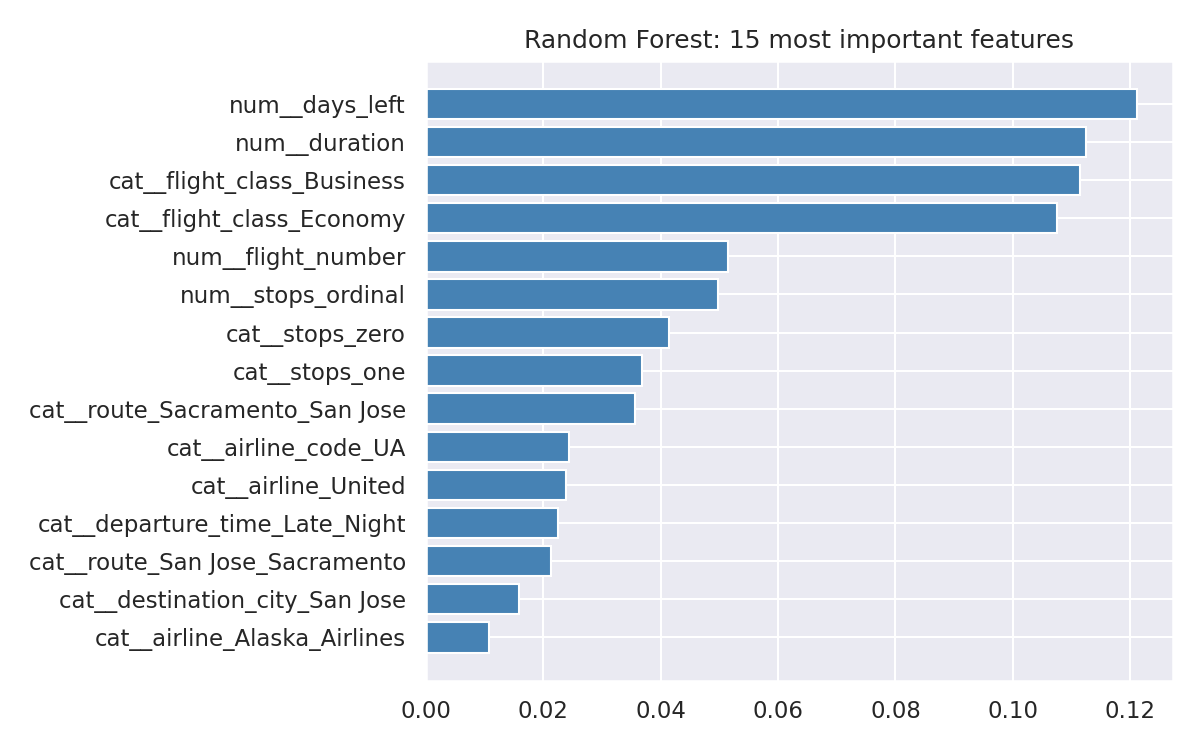

In [28]:
fitted_forest = clone(forest_final).fit(X_train, y_train)
feature_names = fitted_forest.named_steps["prep"].get_feature_names_out()
importances = fitted_forest.named_steps["model"].feature_importances_
importance_table = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False).head(15).sort_values("importance")
)
fig, axis = plt.subplots(figsize=(8, 5))
axis.barh(importance_table["feature"], importance_table["importance"], color="steelblue")
axis.set_title("Random Forest: 15 most important features")
save_figure(fig, "flight_rf_importance.png")
plt.show()
show_table(importance_table.sort_values("importance", ascending=False))

The booking window, the flight length and the seating class are the features which affect the price the most.

## 12. Cross-Validation of Shortlisted Models

We carry out cross validation for the random forest model, the pre-pruned tree and
the log-price Ridge regression model.

We run 5-fold cross validation, 3 times each, giving 15 validation scores per model.

In [29]:
tree_depth12_leaf5 = Pipeline([
    ("prep", plain),
    ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=SEED)),
])

for name, model in [("random_forest_final_5x3", forest_final),
                    ("decision_tree_depth12_leaf5_5x3", tree_depth12_leaf5),
                    ("log_price_ridge_best_5x3", best_log_ridge)]:
    cross_validate_model(name, model, n_repeats=3, note="5 folds x 3 repeats")

show_table(pd.DataFrame([row for row in LOG if "5x3" in row["model"]])[["model", "mean", "std"]])

                             model       mean       std
0          random_forest_final_5x3  121.30003  32.17569
1  decision_tree_depth12_leaf5_5x3  130.01162  31.75086
2         log_price_ridge_best_5x3  124.85694  30.69233

The random forest model maintains the best average, the pre-pruned tree stays about 8 RMSE behind it, and the log-price Ridge is between the two, with standard deviations of about 31 RMSE for all three.

## 13. Metrics Comparison (Full Table)

The table below evaluates one representative configuration per model
family under all three metrics in a single cross-validation pass.

In [30]:
family_models = {
    "linear_regression_ols": baseline_models["linear_regression_ols"],
    "poly_reg_degree2": baseline_models["poly_reg_degree2"],
    "poly_reg_degree2_l2_lambda1": Pipeline([
        ("prep", scaled),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", Ridge(alpha=1.0, random_state=SEED)),
    ]),
    "ridge_reg_l2_lambda10": ridge_lambda10,
    "lasso_reg_l1_lambda0.5": Pipeline([
        ("prep", scaled),
        ("model", Lasso(alpha=best_lasso_lambda, max_iter=20000, random_state=SEED)),
    ]),
    "decision_tree_depth12_leaf5": tree_depth12_leaf5,
    "decision_tree_post_pruned": ccp_tree,
    "random_forest_400_leaf3": forest_final,
    "log_price_ridge_degree2_lambda10": best_log_ridge,
}

full_table = pd.DataFrame([cross_validate_metrics(name, model) for name, model in family_models.items()])
full_table = full_table.sort_values("rmse").reset_index(drop=True)
show_table(full_table)

                              model      rmse      mae      r2
0           random_forest_400_leaf3  121.3729  50.9696  0.7003
1  log_price_ridge_degree2_lambda10  124.9641  55.2974  0.6824
2       decision_tree_depth12_leaf5  128.8190  49.3082  0.6624
3       poly_reg_degree2_l2_lambda1  136.6651  60.8605  0.6120
4         decision_tree_post_pruned  148.3920  65.2080  0.5428
5             ridge_reg_l2_lambda10  152.8509  80.3211  0.5244
6            lasso_reg_l1_lambda0.5  154.1066  80.3302  0.5168
7             linear_regression_ols  154.8221  80.4152  0.5107
8                  poly_reg_degree2  177.2535  62.5587  0.2742

Hence, the random forest model performs the best on all three metrics (about 121.4 RMSE, 51 MAE and 0.70 R2), the log-price polynomial Ridge is the best linear-family model (about 125.0 RMSE, 0.68 R2), and the plain polynomial and unregularised variants are the weakest ones.

## 14. Submission CSV Creation


In [31]:
submission_models = {
    "linear_regression_ols": baseline_models["linear_regression_ols"],
    "poly_reg_degree2": baseline_models["poly_reg_degree2"],
    "ridge_reg_l2_lambda10": ridge_lambda10,
    "lasso_reg_l1_lambda0.5": Pipeline([
        ("prep", scaled),
        ("model", Lasso(alpha=best_lasso_lambda, max_iter=20000, random_state=SEED)),
    ]),
    "decision_tree_depth12_leaf5": tree_depth12_leaf5,
    "decision_tree_post_pruned": ccp_tree,
    "random_forest_400_leaf3": forest_final,
    "log_price_ridge_degree2_lambda10": best_log_ridge,
    "ensemble_forest_log_ridge": VotingRegressor(
        [("forest", forest_final), ("log_price_ridge", best_log_ridge)]
    ),
}

written = []
for name, model in submission_models.items():
    path = fit_and_write_submission(name, model)
    written.append({"model": name, "file": path.name})
show_table(pd.DataFrame(written))

best_frame = pd.read_csv(SUBMISSIONS / "submission_random_forest_400_leaf3.csv")
best_frame.to_csv(SUBMISSIONS / "submission.csv", index=False)
print("upload-ready file: submissions/flight_price/submission.csv")
show_table(best_frame.head())

                              model  \
0             linear_regression_ols   
1                  poly_reg_degree2   
2             ridge_reg_l2_lambda10   
3            lasso_reg_l1_lambda0.5   
4       decision_tree_depth12_leaf5   
5         decision_tree_post_pruned   
6           random_forest_400_leaf3   
7  log_price_ridge_degree2_lambda10   
8         ensemble_forest_log_ridge   

                                              file  
0             submission_linear_regression_ols.csv  
1                  submission_poly_reg_degree2.csv  
2             submission_ridge_reg_l2_lambda10.csv  
3            submission_lasso_reg_l1_lambda0.5.csv  
4       submission_decision_tree_depth12_leaf5.csv  
5         submission_decision_tree_post_pruned.csv  
6           submission_random_forest_400_leaf3.csv  
7  submission_log_price_ridge_degree2_lambda10.csv  
8         submission_ensemble_forest_log_ridge.csv  


upload-ready file: submissions/flight_price/submission.csv


      id       price
0  18395   78.806753
1  11771  174.256207
2  22326  443.556154
3  18332  133.341985
4  11021  532.608014

## 15. Conclusion

* Flight prices are heavily skewed by a handful of exceptionally expensive tickets. This made our squared error metric highly sensitive and explains why the cross-validation scores bounced around so much.
* Cleaning out obvious data errors (like the 25 flights priced at zero) and building custom features really paid off. The airline code, flight number, exact route, and number of stops ended up dominating the Random Forest's feature importance charts.
* Linear models needed tight constraints to work well here. A basic degree-3 polynomial completely overfit the data, leaving us with a rough 380.9 RMSE. Dialing that back to degree-2 and adding a small L2 penalty (Ridge) gave us our best raw-price linear model at 136.7 RMSE. Lasso matched that performance while conveniently ignoring about a third of our features, keeping the model much lighter.
* When tuning the decision trees, setting up limits before training (pre-pruning) worked much better than trimming the tree after it grew (128.8 vs 148 RMSE). This shows that the real signal for flight pricing lies in deep, complex interactions that get destroyed if we aggressively chop off subtrees later.
* Transforming our target to predict the log of the price gave the linear models a solid boost, dropping the Ridge RMSE to 125.0. We tried averaging that log-Ridge model with our Random Forest, which nudged the overall RMSE down to 120.0. However, that tiny improvement was smaller than our normal cross-validation noise, making the ensemble too complex for such a marginal gain.
* We ultimately went with the standalone Random Forest (400 trees, square-root feature sampling, minimum leaf size of 3) as the final model. It was incredibly stable across repeated testing, delivering a ~121.4 RMSE, 51 MAE, and an R² of 0.70.